## Notebook 3 – Data Quality Assessment
### Missing Values

Missing values occur when no data is stored for a particular column in a row.

These values are typically represented as:

- NaN
- None
- NULL

#### Example Dataset


In [1]:
import pandas as pd
import numpy as np
 
data = {
"CustomerID": ["C001", "C002", "C003", "C004", "C005"],
"Age": [25, 32, np.nan, 28, 35],
"MonthlyIncome": [35000, 50000, 65000, np.nan, 58000],
"Gender": ["Male", "Female", "Male", None, "Male"],
"City": ["Hyderabad", "Chennai", "Bangalore", "Mumbai", None],
"Churn": ["No", "Yes", "No", "No", "Yes"]
}
 
df = pd.DataFrame(data)
 
df

,CustomerID,Age,MonthlyIncome,Gender,City,Churn
0,C001,25.0,35000.0,Male,Hyderabad,No
1,C002,32.0,50000.0,Female,Chennai,Yes
2,C003,NaN,65000.0,Male,Bangalore,No
3,C004,28.0,NaN,NaN,Mumbai,No
4,C005,35.0,58000.0,Male,NaN,Yes


### 1. Number of Missing Values

To Find the total number of missing values in the entire dataset.

In [3]:
df.isnull().sum().sum()

np.int64(4)

To Find the total number of missing values in each column of dataset.

In [4]:
df.isnull().sum()

CustomerID       0
Age              1
MonthlyIncome    1
Gender           1
City             1
Churn            0
dtype: int64

### 2. Percentage of Missing Values

Percentage of missing values helps us understand the severity of missing data.

Formula for percentage calculation :(Missing Values / Total Values) × 100

In [6]:
missing_percentage = (     df.isnull().sum().sum()    /    (df.shape[0] * df.shape[1])   ) * 100

print(missing_percentage)

13.333333333333334


To get the Column-wise Missing Percentage

In [7]:


(df.isnull().sum() / len(df)) * 100

CustomerID        0.0
Age              20.0
MonthlyIncome    20.0
Gender           20.0
City             20.0
Churn             0.0
dtype: float64

### 3. Missing Values by Column

This analysis identifies which columns contain missing values.

to get Missing values by column 

In [8]:
df.isnull().sum()

CustomerID       0
Age              1
MonthlyIncome    1
Gender           1
City             1
Churn            0
dtype: int64

**View Only Columns With Missing Values**

In [11]:

df.isnull().sum()[df.isnull().sum() > 0]

Age              1
MonthlyIncome    1
Gender           1
City             1
dtype: int64

In [12]:
df[df.isnull().any(axis=1)]   #This displays every row containing at least one missing value.

,CustomerID,Age,MonthlyIncome,Gender,City,Churn
2,C003,NaN,65000.0,Male,Bangalore,No
3,C004,28.0,NaN,NaN,Mumbai,No
4,C005,35.0,58000.0,Male,NaN,Yes


### 4. Missing Value Patterns

Missing value patterns refer to identifying and understanding where missing values occur in a dataset, how frequently they occur, and whether they follow a particular pattern across rows or columns

#### Visualize Missing Values
#### Method 1

In [13]:
df.isnull()

,CustomerID,Age,MonthlyIncome,Gender,City,Churn
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,True,False,False,False,False
3,False,False,True,True,False,False
4,False,False,False,False,True,False


#### Method 2: Heatmap

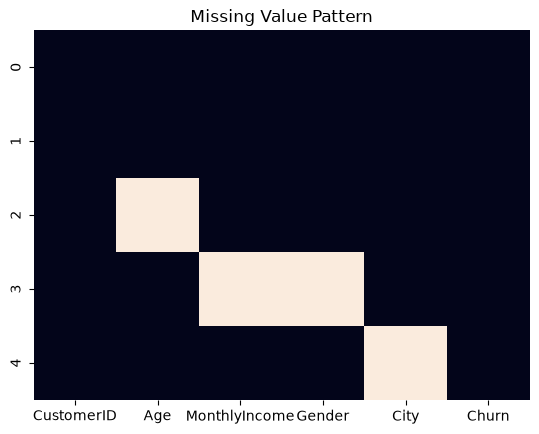

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
 
sns.heatmap(df.isnull(), cbar=False)
 
plt.title("Missing Value Pattern")
plt.show()

Interpretation

Black/Colored Cell:  Missing Value Present

White Cell: Value Available

#### Find Rows With Missing Values

In [16]:

df[df.isnull().any(axis=1)]

,CustomerID,Age,MonthlyIncome,Gender,City,Churn
2,C003,NaN,65000.0,Male,Bangalore,No
3,C004,28.0,NaN,NaN,Mumbai,No
4,C005,35.0,58000.0,Male,NaN,Yes


In [17]:
df.isnull().sum(axis=1) #Count Missing Values Per Row

0    0
1    0
2    1
3    2
4    1
dtype: int64

#### Types of Missing Value Patterns

| Type                                | Meaning                                                                            | Example                                                                                       |
| ----------------------------------- | ---------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------------- |
| MCAR (Missing Completely At Random) | Missingness is unrelated to the data values or other variables.                    | Some survey responses are lost because of a random technical error.                           |
| MAR (Missing At Random)             | Missingness depends on other observed variables.                                   | Younger participants are less likely to report their income.                                  |
| MNAR (Missing Not At Random)        | Missingness depends on the missing value itself or related unobserved information. | People with very high incomes may be less likely to disclose their income because it is high. |


#### Missing Value Analysis in Pandas

| S.No. | Task                      | Code                                   | Description                                                            |
| :---: | ------------------------- | -------------------------------------- | ---------------------------------------------------------------------- |
|   1   | Total Missing Values      | `df.isnull().sum().sum()`              | Counts the total number of missing values across the entire DataFrame. |
|   2   | Missing Values per Column | `df.isnull().sum()`                    | Counts the missing values in each column.                              |
|   3   | Missing Value Percentage  | `(df.isnull().sum() / len(df)) * 100`  | Calculates the percentage of missing values in each column.            |
|   4   | Rows with Missing Values  | `df[df.isnull().any(axis=1)]`          | Displays all rows containing at least one missing value.               |
|   5   | Missing Values per Row    | `df.isnull().sum(axis=1)`              | Counts the missing values in each row.                                 |
|   6   | Missing Pattern Heatmap   | `sns.heatmap(df.isnull(), cbar=False)` | Visualizes the locations of missing values across rows and columns.    |



#### AI ML use case:

Machine Learning algorithms learn patterns from data. If the data contains missing values, the model may:

- Throw errors
- Learn incorrect patterns
- Produce inaccurate predictions
- Become biased

Missing values can negatively affect machine learning models by causing errors, reducing prediction accuracy, and introducing bias. Analyzing missing values helps determine appropriate data cleaning strategies such as imputation or removal before model training.

### Duplicate Records

Duplicate records occur when the same information appears more than once in a dataset.

#### 1.Identify Duplicates

The duplicated() method in Pandas identifies rows that have already appeared earlier in a DataFrame and marks repeated occurrences as True.

#### Example

In [22]:
import pandas as pd

data = {
    "Name": ["Hari", "Kumar", "Ravi", "Hari", "Priya", "Kumar"],
    "Age": [22, 25, 23, 22, 24, 25],
    "City": ["Chittoor", "Bangalore", "Chennai", "Chittoor", "Hyderabad", "Bangalore"]
}

df = pd.DataFrame(data)
print(df)
print("\n",df.duplicated())

    Name  Age       City
0   Hari   22   Chittoor
1  Kumar   25  Bangalore
2   Ravi   23    Chennai
3   Hari   22   Chittoor
4  Priya   24  Hyderabad
5  Kumar   25  Bangalore

 0    False
1    False
2    False
3     True
4    False
5     True
dtype: bool


- Row 0: False because it appears for the first time.
- Row 3: True because its values match row 0.
- Row 5: True because its values match row 1.

Important: By default, duplicated() marks the first occurrence as False and subsequent occurrences as True.

#### 2. Count Duplicates — duplicated().sum()


Counts the number of duplicate rows identified by duplicated().

In [23]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 2


**Count All Occurrences in Duplicate Groups**

If you want to count every row belonging to a duplicate group, including the first occurrence, use:


In [24]:

df.duplicated(keep=False).sum()

np.int64(4)

Why 4? Because rows 0 and 3 form one duplicate group, while rows 1 and 5 form another. Both occurrences in each group are counted.

#### 3. Identify Completely Duplicated Rows


Completely duplicated rows are rows in which every column value matches another row.

You can use duplicated() to identify them and display the actual records.

example:

Display Duplicate Rows Only

In [25]:
duplicate_rows = df[df.duplicated()]

print(duplicate_rows)

    Name  Age       City
3   Hari   22   Chittoor
5  Kumar   25  Bangalore


example Display Every Row in a Duplicate Group

In [26]:
duplicate_rows = df[df.duplicated(keep=False)]

print(duplicate_rows)

    Name  Age       City
0   Hari   22   Chittoor
1  Kumar   25  Bangalore
3   Hari   22   Chittoor
5  Kumar   25  Bangalore


#### 4. Identify Potential Duplicate Records

Potential duplicates are records that are not completely identical but appear to represent the same entity.

Potential duplicate records are rows that may represent the same real-world entity, even when their values are not completely identical.

For example, the same person might appear twice because their name is formatted differently or their city is spelled differently.

#### Example

In [3]:
import pandas as pd
data = {
    "Name": ["Hari Kishore", "Hari Kishore", "Kumar", "Ravi"],
    "Age": [22, 22, 25, 23],
    "City": ["Chittoor", "Chittoor ", "Bangalore", "Chennai"]
}

df = pd.DataFrame(data)

print(df)

           Name  Age       City
0  Hari Kishore   22   Chittoor
1  Hari Kishore   22  Chittoor 
2         Kumar   25  Bangalore
3          Ravi   23    Chennai


Here, the first two records may represent the same person. However, the second record has an extra space after "Chittoor".

#### Identify Potential Duplicates Using Selected Columns

Suppose you want to identify records with the same name and age, regardless of their city.





In [8]:
df[df.duplicated(subset=["Name", "Age"], keep=False)]

,Name,Age,City
0,Hari Kishore,22,Chittoor
1,Hari Kishore,22,Chittoor


This identifies rows sharing the same combination of Name and Age.

- duplicated() → Identifies duplicate rows.
- duplicated().sum() → Counts duplicate rows.
- df[df.duplicated()] → Displays duplicate rows.
- subset → Checks duplicates using selected columns.
- drop_duplicates() → Removes duplicate rows.

#### AI ML case:

AI/ML best practice: If duplicate records represent the same underlying entity, split the data appropriately to prevent information leakage between training and test sets. Whether to remove duplicates depends on the dataset and the problem.

### Invalid Values


Invalid values are data values that violate the expected rules, constraints, or valid range for a particular feature in a dataset.

Invalid values are data values that do not make logical, business, or real-world sense.

Even if the data type is correct, the value itself may be incorrect.

#### example

For example:

- Negative age (-5) is invalid.
- Negative salary (-20000) is usually invalid.
- Negative temperature (-5°C) can be valid.

Important: A negative value is not always invalid. Its validity depends on the meaning of the column.

#### 1.Identify Negative Values Where Inappropriate

Some columns should never contain negative values.

Examples:

- Plain Text
- Age
- Salary
- Quantity
- Height
- Weight
- Experience

In [17]:
import pandas as pd

data = {
    "Name": ["Hari", "Kumar", "Ravi", "Priya", "Arun"],
    "Age": [22, -5, 25, 24, -2],
    "Salary": [25000, 30000, -15000, 40000, 35000]
}

df = pd.DataFrame(data)
print(df,"\n")


    Name  Age  Salary
0   Hari   22   25000
1  Kumar   -5   30000
2   Ravi   25  -15000
3  Priya   24   40000
4   Arun   -2   35000 



In [16]:
df[df["Age"]< 0]  #identifying the -ve values

,Name,Age,Salary
1,Kumar,-5,30000
4,Arun,-2,35000


**Check Multiple Columns**


In [15]:
df[(df['Age'] < 0) | (df['Salary'] < 0)]

,Name,Age,Salary
1,Kumar,-5,30000
2,Ravi,25,-15000
4,Arun,-2,35000


#### Count Negative Values in Each Column


In [18]:
(df[["Age", "Salary"]] < 0).sum()

Age       2
Salary    1
dtype: int64

#### 2.Impossible Values

Impossible values are data values that violate logical rules or the physical or domain-specific limits of a feature.

Examples:

- Age = -5 → Impossible for a person's age in a typical age-in-years dataset.
- Age = 250 → Impossible for a human age in a typical dataset.
- Month = 15 → Impossible because a year has only 12 months.
- Percentage = 150 → Impossible when the feature represents a percentage bounded between 0 and 100.

Important: What counts as impossible depends on the meaning and valid range of the feature.

Impossible values are values outside the realistic range.

#### example:

In [21]:
import pandas as pd

data = {
    "Name": ["Hari", "Kumar", "Ravi", "Priya", "Arun"],
    "Age": [22, 250, 25, -5, 24],
    "Percentage": [85, 150, 75, 90, -10],
    "Month": [10, 15, 6, 12, 3]
}

df = pd.DataFrame(data)

print(df)

    Name  Age  Percentage  Month
0   Hari   22          85     10
1  Kumar  250         150     15
2   Ravi   25          75      6
3  Priya   -5          90     12
4   Arun   24         -10      3


#### Identify Impossible Ages

Assume the dataset contains human ages in years, and the acceptable range for this analysis is 0–120.

In [23]:
df[(df["Age"]<0) | (df["Age"]>120)]

,Name,Age,Percentage,Month
1,Kumar,250,150,15
3,Priya,-5,90,12


#### Identify Impossible Percentages

Assume the percentage must be between 0 and 100.

In [24]:
df[(df["Percentage"] < 0) | (df["Percentage"] > 100)]

,Name,Age,Percentage,Month
1,Kumar,250,150,15
4,Arun,24,-10,3


In [25]:
print("Invalid ages:", ((df["Age"] < 0) | (df["Age"] > 120)).sum())

print("Invalid percentages:", ((df["Percentage"] < 0) | (df["Percentage"] > 100)).sum())

print("Invalid months:", ((df["Month"] < 1) | (df["Month"] > 12)).sum())

Invalid ages: 2
Invalid percentages: 2
Invalid months: 1


#### 3. Incorrect Categories

They commonly occur because of human data-entry errors or inconsistent data collection.

Examples:

- "Male", "male", "MALE" → Different representations of the same category.
- "Bangalore", "Banglore" → A spelling inconsistency.
- "Hyderabad", "Hyderbad" → A spelling error.
- "Yes", "Yess" → An inconsistent category.

Incorrect categories can cause problems during data analysis and machine learning if they are not identified and handled appropriately.

#### example:


In [26]:
import pandas as pd

data = {
    "Name": ["Hari", "Kumar", "Ravi", "Priya", "Arun", "Sneha"],
    "Gender": ["Male", "male", "FEMALE", "Female", "Mle", "Male"],
    "City": ["Bangalore", "Bengaluru", "Hyderabad", "Hyderbad", "Chennai", "Chennai"],
    "Purchased": ["Yes", "No", "YES", "Yess", "No", "Yes"]
}

df = pd.DataFrame(data)

print(df)

    Name  Gender       City Purchased
0   Hari    Male  Bangalore       Yes
1  Kumar    male  Bengaluru        No
2   Ravi  FEMALE  Hyderabad       YES
3  Priya  Female   Hyderbad      Yess
4   Arun     Mle    Chennai        No
5  Sneha    Male    Chennai       Yes


Notice the inconsistencies:

- Gender: "Male", "male", and "Mle".
- City: "Bangalore" and "Bengaluru" may represent the same city; "Hyderbad" is misspelled.
- Purchased: "Yes", "YES", and "Yess".

#### Identify Incorrect Categories

#### A. Display Unique Categories

 Use unique() to display the distinct values present in a categorical column.

In [27]:
df["Gender"].unique()   ## This reveals inconsistent capitalization and a potential spelling error.

<ArrowStringArray>
['Male', 'male', 'FEMALE', 'Female', 'Mle']
Length: 5, dtype: str

#### Count Categories

Use value_counts() to understand how frequently each category appears.





In [28]:
df["Gender"].value_counts()

Gender
Male      2
male      1
FEMALE    1
Female    1
Mle       1
Name: count, dtype: int64

This helps identify categories that may be misspelled or inconsistently represented.

Important: A category appearing only once is not necessarily incorrect. Investigate the values using domain knowledge.

#### Check Categories Against an Expected List

Suppose the only valid gender categories for this example are "Male" and "Female".


In [29]:

valid_genders = ["Male", "Female"]

df[~df["Gender"].isin(valid_genders)]

,Name,Gender,City,Purchased
1,Kumar,male,Bengaluru,No
2,Ravi,FEMALE,Hyderabad,YES
4,Arun,Mle,Chennai,No


#### Correct Incorrect Categories
A. Standardize Capitalization and Whitespace

In [30]:
df["Gender"] = df["Gender"].str.strip().str.title()

This removes leading and trailing spaces and standardizes capitalization.

For example:

"male" → "Male"
"FEMALE" → "Female"

However, it does not automatically correct "Mle".

#### Correct Spelling Errors Using replace()


In [31]:
df["Gender"] = df["Gender"].replace({
    "Mle": "Male"
})

### 4. Invalid Dates

Invalid dates are date values that do not represent valid calendar dates or do not follow the expected date format.

Invalid dates can occur because of data-entry errors, incorrect formats, or values that do not exist on the calendar.

Examples:

- 2026-13-10 → Invalid month because months range from 1 to 12.
- 2026-02-30 → Invalid because February does not have 30 days.
- 2026-04-31 → Invalid because April has only 30 days.
- 15-25-2026 → Invalid if the expected format is DD-MM-YYYY.

Important: A date may look different from the expected format without being invalid. For example, 31-12-2026 is a valid date in DD-MM-YYYY format.

#### Example Dataset

In [32]:
import pandas as pd

data = {
    "Name": ["Hari", "Kumar", "Ravi", "Priya", "Arun"],
    "Date": [
        "2026-10-25",
        "2026-02-30",
        "2026-13-10",
        "2026-04-15",
        "invalid_date"
    ]
}

df = pd.DataFrame(data)

print(df)

    Name          Date
0   Hari    2026-10-25
1  Kumar    2026-02-30
2   Ravi    2026-13-10
3  Priya    2026-04-15
4   Arun  invalid_date


#### Identify Invalid Dates Using pd.to_datetime()

The pd.to_datetime() function converts values into Pandas datetime objects. With errors="coerce", values that cannot be converted become NaT (Not a Time).

In [34]:
df["Date_Converted"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

print(df)

    Name          Date Date_Converted
0   Hari    2026-10-25     2026-10-25
1  Kumar    2026-02-30            NaT
2   Ravi    2026-13-10            NaT
3  Priya    2026-04-15     2026-04-15
4   Arun  invalid_date            NaT


#### Display Only Invalid Dates

In [35]:
invalid_dates = df[df["Date_Converted"].isna()]

print(invalid_dates)

    Name          Date Date_Converted
1  Kumar    2026-02-30            NaT
2   Ravi    2026-13-10            NaT
4   Arun  invalid_date            NaT


Important: This approach also identifies missing dates, if the original column contains missing values. To distinguish missing values from invalid non-empty dates, check the original column separately.

In [37]:
invalid_dates = df[
    df["Date"].notna() &
    df["Date_Converted"].isna()
]  #This identifies non-missing values that failed conversion.

print(invalid_dates)

    Name          Date Date_Converted
1  Kumar    2026-02-30            NaT
2   Ravi    2026-13-10            NaT
4   Arun  invalid_date            NaT


#### Identify Invalid Dates in a Specific Format

Suppose dates must follow the DD-MM-YYYY format.



In [38]:
df = pd.DataFrame({
    "Date": [
        "25-10-2026",
        "30-02-2026",
        "15-12-2026",
        "2026-10-25"
    ]
})

df["Date_Converted"] = pd.to_datetime(
    df["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print(df)



         Date Date_Converted
0  25-10-2026     2026-10-25
1  30-02-2026            NaT
2  15-12-2026     2026-12-15
3  2026-10-25            NaT


Here, values that do not match the specified format or represent an invalid calendar date are converted to NaT.

### 5. Incorrect Data Types

Incorrect data types occur when a column's data type does not match the actual meaning or intended use of its values.

For example:

- Age stored as text (object) instead of a numerical type.
- Salary stored as strings instead of numbers.
- Date values stored as strings instead of datetime values.
- Product IDs stored as numbers even though they represent identifiers rather than quantities.

Incorrect data types can cause errors in calculations, data analysis, and machine learning preprocessing.

#### Example Dataset

In [39]:
import pandas as pd

data = {
    "Name": ["Hari", "Kumar", "Ravi", "Priya"],
    "Age": ["22", "25", "23", "24"],
    "Salary": ["25000", "35000", "30000", "40000"],
    "Joining_Date": ["2026-01-15", "2026-02-10", "2026-03-05", "2026-04-20"]
}

df = pd.DataFrame(data)

print(df.dtypes)

Name            str
Age             str
Salary          str
Joining_Date    str
dtype: object


Here, Age, Salary, and Joining_Date are stored as text (object), even though they represent numerical and date values

#### Identify Incorrect Data Types

#### A. Check Data Types Using dtypes

Definition: The dtypes attribute displays the data type of each DataFrame column.

df.dtypes

Use this to identify columns whose data types may not match their intended purpose.

In [40]:
df.dtypes


Name            str
Age             str
Salary          str
Joining_Date    str
dtype: object

#### B. Check Data Types Using info()

df.info()

This displays column names, data types, non-null counts, and memory usage.

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Name          4 non-null      str  
 1   Age           4 non-null      str  
 2   Salary        4 non-null      str  
 3   Joining_Date  4 non-null      str  
dtypes: str(4)
memory usage: 346.0 bytes


#### Correct Incorrect Data Types
A. Convert Text to Integer

Use astype() when the values can be converted directly.


In [45]:
df["Age"] = df["Age"].astype(int)

df["Age"].dtypes

dtype('int64')

#### Convert Text to Datetime

Use pd.to_datetime() to convert date strings into datetime values.


In [49]:
df["Joining_Date"] = pd.to_datetime(
    df["Joining_Date"],
    format="%Y-%m-%d",
    errors="coerce"
)

df.dtypes

Name                       str
Age                      int64
Salary                     str
Joining_Date    datetime64[us]
dtype: object

#### What If the Column Contains Invalid Values?

Consider an age column containing "22", "25", "unknown", and "24".

Direct conversion using astype(int) will fail because "unknown" cannot be converted into an integer.

Use pd.to_numeric() instead:

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

Values that cannot be converted become NaN.

Important: Investigate these missing values before deciding whether to replace or remove them.

In [50]:
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

#### 6. Unexpected Values

Unexpected values are data values that are unusual, inconsistent with expectations, or outside the anticipated set of values for a column, but are not necessarily invalid.

They may occur because of data-entry mistakes, inconsistent data collection, unusual real-world observations, or changes in business rules.

Examples:

- Age = 150 → Unexpected for a typical human dataset and potentially invalid.
- Salary = 1000000 → May be unusual but could be valid.
- Gender = "Unknown" → May be unexpected if the dataset uses only "Male" and "Female".
- Temperature = -10°C → May be unexpected in a particular dataset but is physically possible.

Important: An unexpected value is not automatically an incorrect value. Investigate it before deciding how to handle it.

#### Example Dataset

In [51]:
import pandas as pd

data = {
    "Name": ["Hari", "Kumar", "Ravi", "Priya", "Arun", "Sneha"],
    "Age": [22, 25, 23, 150, 24, 21],
    "Salary": [25000, 35000, 30000, 1000000, 40000, 28000],
    "City": [
        "Chittoor",
        "Bangalore",
        "Chennai",
        "Unknown",
        "Hyderabad",
        "Chittoor"
    ]
}

df = pd.DataFrame(data)

print(df)

    Name  Age   Salary       City
0   Hari   22    25000   Chittoor
1  Kumar   25    35000  Bangalore
2   Ravi   23    30000    Chennai
3  Priya  150  1000000    Unknown
4   Arun   24    40000  Hyderabad
5  Sneha   21    28000   Chittoor


In this dataset:

- Age = 150 is an unexpected age that should be investigated.
- Salary = 1000000 is unusually high compared with the other salaries, but it may be correct.
- City = "Unknown" may require investigation or special handling.

#### Identify Unexpected Values

#### A. Identify Values Outside an Expected Range

Suppose the acceptable age range for this analysis is 0–120 years.

df[(df["Age"] < 0) | (df["Age"] > 120)]

This identifies records with ages outside the specified range.

Note: The range should be chosen based on the dataset's contex

In [52]:
df[(df["Age"] < 0) | (df["Age"] > 120)]

,Name,Age,Salary,City
3,Priya,150,1000000,Unknown


#### B. Identify Unexpected Categories

Suppose the expected cities are Chittoor, Bangalore, Chennai, and Hyderabad.



In [53]:
expected_cities = [
    "Chittoor",
    "Bangalore",
    "Chennai",
    "Hyderabad"
]

df[~df["City"].isin(expected_cities)]  #This returns records whose city values are not in the expected list, including "Unknown".


,Name,Age,Salary,City
3,Priya,150,1000000,Unknown


#### Inspect Unique Values

In [54]:
df["City"].unique()

<ArrowStringArray>
['Chittoor', 'Bangalore', 'Chennai', 'Unknown', 'Hyderabad']
Length: 5, dtype: str

#### Identify Unusually High or Low Numerical Values

Unexpected numerical values can sometimes be investigated using summary statistics.



This displays the count, mean, standard deviation, minimum, quartiles, and maximum salary.

In [55]:
df["Salary"].describe()

count          6.000000
mean      193000.000000
std       395383.358274
min        25000.000000
25%        28500.000000
50%        32500.000000
75%        38750.000000
max      1000000.000000
Name: Salary, dtype: float64

To investigate salaries above a threshold chosen for the dataset:

df[df["Salary"] > 100000]

This identifies salaries greater than ₹100,000.

Important: A threshold is not proof that a value is wrong. It is a way to flag records for further investigation.

In [56]:

df[df["Salary"] > 100000]

,Name,Age,Salary,City
3,Priya,150,1000000,Unknown


### 7. Empty Strings

An empty string is a text value that contains no characters, represented by "" or ''.

In Pandas, empty strings are not automatically treated as missing values (NaN). Therefore, they must be identified separately during data inspection and EDA.

Example:

- "Hari" → Contains text.
- "" → Empty string.
- " " → Contains a space, so it is not technically an empty string.
- NaN → Represents a missing value.

#### Example Dataset


In [57]:
import pandas as pd
import numpy as np

data = {
    "Name": ["Hari", "", "Ravi", "Priya", " "],
    "Age": [22, 25, 23, np.nan, 24],
    "City": ["Chittoor", "Bangalore", "", "Hyderabad", "Chennai"]
}

df = pd.DataFrame(data)

print(df)

    Name   Age       City
0   Hari  22.0   Chittoor
1         25.0  Bangalore
2   Ravi  23.0           
3  Priya   NaN  Hyderabad
4         24.0    Chennai


#### Identify Empty Strings
A. Identify Empty Strings in a Single Column

Definition: Use a comparison with "" to identify values that contain no characters.

This returns rows where the Name column contains an empty string.

In [58]:
df[df["Name"] == ""]

,Name,Age,City
1,,25.0,Bangalore


#### Identify Empty Strings Across All Columns


This counts empty strings in each column.

In [59]:
df.eq("").sum()

Name    1
Age     0
City    1
dtype: int64

#### Identify Whitespace-Only Strings

A value containing spaces, such as " ", is not equal to "".

To identify both empty strings and whitespace-only strings in text columns:

df["Name"].str.strip().eq("")

This returns True for both "" and strings containing only whitespace.

In [60]:
df["Name"].str.strip().eq("")


0    False
1     True
2    False
3    False
4     True
Name: Name, dtype: bool

#### Replace Empty Strings

In [61]:
df = df.replace("", np.nan)

#### Replace Empty and Whitespace-Only Strings

This replaces empty strings and strings containing only whitespace with NaN.



In [ ]:
df = df.replace(r"^\s*$", np.nan, regex=True)

In [ ]:
# Afterward, you can inspect missing values using:

df.isnull().sum()

### 8. Null-like Values

Null-like values are values that represent missing, unavailable, or undefined information in a dataset.

They may appear in different forms, such as None, NaN, NaT, "NULL", "null", "N/A", or "None".

Important: Pandas recognizes some values, such as None, NaN, and NaT, as missing values. However, strings such as "NULL", "null", "N/A", and "None" are usually treated as ordinary text until you explicitly convert them.

#### example:

In [62]:
import pandas as pd
import numpy as np

data = {
    "Name": ["Hari", "Kumar", "Ravi", "Priya", "Arun", "Sneha"],
    "Age": [22, np.nan, 23, None, 25, 24],
    "City": ["Chittoor", "NULL", "N/A", "Hyderabad", "None", "Bangalore"]
}

df = pd.DataFrame(data)

print(df)

    Name   Age       City
0   Hari  22.0   Chittoor
1  Kumar   NaN       NULL
2   Ravi  23.0        N/A
3  Priya   NaN  Hyderabad
4   Arun  25.0       None
5  Sneha  24.0  Bangalore


Here:

- NaN and None in the Age column represent missing values.
- "NULL", "N/A", and "None" in the City column are strings and are not automatically recognized as missing values.

#### Identify Null-like Values

A. Identify Recognized Missing Values

Use isnull() or isna() to identify missing values that Pandas recognizes.

df.isnull()

This returns True for recognized missing values and False for other values.

In [ ]:
null_like = ['NA', 'N/A', 'NULL', 'null', 'None', '-', '?']
 
df[df['City'].isin(null_like)]

#### Convert to Actual Missing Values

In [63]:
df.replace(
['NA', 'N/A', 'NULL', 'null', 'None', '-', '?'],
np.nan,
inplace=True
)

,Name,Age,City
0,Hari,22.0,Chittoor
1,Kumar,NaN,NaN
2,Ravi,23.0,NaN
3,Priya,NaN,Hyderabad
4,Arun,25.0,NaN
5,Sneha,24.0,Bangalore


#### AI/ML Data Quality Pipeline